In [1]:
import os
import numpy as np
import argparse
import sklearn
import pandas as pd
import scanpy as sc
import scipy as sp
import anndata
from sklearn.decomposition import PCA
from operator import itemgetter
import random
import matplotlib.pyplot as plt
import umap.umap_ as umap
import time
import torch

from spiral.main import SPIRAL_integration
from spiral.layers import *
from spiral.utils import *
from spiral.CoordAlignment import CoordAlignment

# Set environment variables
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

In [2]:
# for loading DLPFC12 data·
def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC/', section_id='151507'):
    # 151507, ..., 151676 12 in total
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5',
                        load_images=True)
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    # print(ad.obs)
    return ad

In [3]:
def Cal_Spatial_Net(adata, rad_cutoff=None, k_cutoff=None, model='Radius', verbose=True):
    """\
    Construct the spatial neighbor networks.

    Parameters
    ----------
    adata
        AnnData object of scanpy package.
    rad_cutoff
        radius cutoff when model='Radius'
    k_cutoff
        The number of nearest neighbors when model='KNN'
    model
        The network construction model. When model=='Radius', the spot is connected to spots whose distance is less than rad_cutoff. When model=='KNN', the spot is connected to its first k_cutoff nearest neighbors.

    Returns
    -------
    The spatial networks are saved in adata.uns['Spatial_Net']
    """

    assert (model in ['Radius', 'KNN'])
    if verbose:
        print('------Calculating spatial graph...')
    coor = pd.DataFrame(adata.obsm['spatial'])
    coor.index = adata.obs.index
    #     coor.columns = ['imagerow', 'imagecol']

    if model == 'Radius':
        nbrs = sklearn.neighbors.NearestNeighbors(radius=rad_cutoff).fit(coor)
        distances, indices = nbrs.radius_neighbors(coor, return_distance=True)
        KNN_list = []
        for it in range(indices.shape[0]):
            KNN_list.append(pd.DataFrame(zip([it] * indices[it].shape[0], indices[it], distances[it])))

    if model == 'KNN':
        nbrs = sklearn.neighbors.NearestNeighbors(n_neighbors=k_cutoff + 1).fit(coor)
        distances, indices = nbrs.kneighbors(coor)
        KNN_list = []
        for it in range(indices.shape[0]):
            KNN_list.append(pd.DataFrame(zip([it] * indices.shape[1], indices[it, :], distances[it, :])))

    KNN_df = pd.concat(KNN_list)
    KNN_df.columns = ['Cell1', 'Cell2', 'Distance']

    Spatial_Net = KNN_df.copy()
    Spatial_Net = Spatial_Net.loc[Spatial_Net['Distance'] > 0,]
    id_cell_trans = dict(zip(range(coor.shape[0]), np.array(coor.index), ))
    Spatial_Net['Cell1'] = Spatial_Net['Cell1'].map(id_cell_trans)
    Spatial_Net['Cell2'] = Spatial_Net['Cell2'].map(id_cell_trans)
    if verbose:
        print('The graph contains %d edges, %d cells.' % (Spatial_Net.shape[0], adata.n_obs))
        print('%.4f neighbors per cell on average.' % (Spatial_Net.shape[0] / adata.n_obs))

    adata.uns['Spatial_Net'] = Spatial_Net

In [4]:
# dirs = r"C:\Code\Data\DLPFC"
#
# # lists=[[151507,151508],[151508,151509],[151509,151510],[151669,151670],[151670,151671],[151671,151672],[151673,151674],[151674,151675],[151675,151676]]
# lists = [[151507, 151508, 151509, 151510], [151669, 151670, 151671, 151672], [151673, 151674, 151675, 151676]]
# out_dirs = "C:\Code\Data\DLPFC/"
#
# for sample_name in lists:
#     # IDX=np.arange(0,2)
#     IDX = np.arange(0, 4)
#     VF = []
#     MAT = []
#     flags = str(sample_name[IDX[0]])
#     for i in np.arange(1, len(IDX)):
#         flags = flags + '-' + str(sample_name[IDX[i]])
#     flags = flags + "_"
#     for k in np.arange(len(IDX)):
#         adata = load_DLPFC(root_dir=dirs, section_id=str(sample_name[k]))
#         adata.var_names_make_unique()
#
#         sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
#         sc.pp.normalize_total(adata, target_sum=1e4)
#         sc.pp.log1p(adata)
#
#         adata.obs['batch'] = str(sample_name[IDX[k]])
#         cells = [str(sample_name[IDX[k]]) + '-' + i for i in adata.obs_names]
#         mat1 = pd.DataFrame(adata.X.toarray(), columns=adata.var_names, index=cells)
#         coord1 = pd.DataFrame(adata.obsm['spatial'], columns=['x', 'y'], index=cells)
#         meta1 = adata.obs[['original_clusters', 'batch']]
#         meta1.columns = ['celltype', 'batch']
#         meta1.index = cells
#         meta1.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[k]]) + "_label-1.txt")
#         coord1.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[k]]) + "_positions-1.txt")
#         MAT.append(mat1)
#         VF = np.union1d(VF, adata.var_names[adata.var['highly_variable']])
#
#     for i in np.arange(len(IDX)):
#         mat = MAT[i]
#         mat = mat.loc[:, VF]
#         mat.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[i]]) + "_features-1.txt")

In [5]:
# rad = 150
# KNN = 6
#
# # lists=[[151507,151508],[151508,151509],[151509,151510],[151669,151670],[151670,151671],[151671,151672],[151673,151674],[151674,151675],[151675,151676]]
# lists = [[151507, 151508, 151509, 151510], [151669, 151670, 151671, 151672], [151673, 151674, 151675, 151676]]
# dirs = r"C:\Code\Data\DLPFC/"
#
# # dirs="/home/yunfei/spatial_benchmarking/benchmarking_data/DLPFC12"
# # sample_name=[151507,151508,151509,151510,151669,151670,151671,151672,151673,151674,151675,151676]
# for sample_name in lists:
#     # IDX=[0,1]
#     IDX = [0, 1, 2, 3]
#     flags = str(sample_name[IDX[0]])
#     for i in np.arange(1, len(IDX)):
#         flags = flags + '-' + str(sample_name[IDX[i]])
#     for i in IDX:
#         sample1 = sample_name[i]
#         features = pd.read_csv(dirs + "gtt_input_scanpy/" + flags + '_' + str(sample1) + "_features-1.txt", header=0,
#                                index_col=0, sep=',')
#         meta = pd.read_csv(dirs + "gtt_input_scanpy/" + flags + '_' + str(sample1) + "_label-1.txt", header=0,
#                            index_col=0, sep=',')
#         coord = pd.read_csv(dirs + "gtt_input_scanpy/" + flags + '_' + str(sample1) + "_positions-1.txt", header=0,
#                             index_col=0, sep=',')
#         # meta=meta.iloc[:meta.shape[0]-1,:]
#         adata = sc.AnnData(features)
#         adata.var_names_make_unique()
#         adata.X = sp.csr_matrix(adata.X)
#         adata.obsm["spatial"] = coord.loc[:, ['x', 'y']].to_numpy()
#         Cal_Spatial_Net(adata, rad_cutoff=rad, k_cutoff=6, model='KNN', verbose=True)
#         if 'highly_variable' in adata.var.columns:
#             adata_Vars = adata[:, adata.var['highly_variable']]
#         else:
#             adata_Vars = adata
#         features = pd.DataFrame(adata_Vars.X.toarray()[:, ], index=adata_Vars.obs.index, columns=adata_Vars.var.index)
#         cells = np.array(features.index)
#         cells_id_tran = dict(zip(cells, range(cells.shape[0])))
#         if 'Spatial_Net' not in adata.uns.keys():
#             raise ValueError("Spatial_Net is not existed! Run Cal_Spatial_Net first!")
#
#         Spatial_Net = adata.uns['Spatial_Net']
#         G_df = Spatial_Net.copy()
#         np.savetxt(dirs + "gtt_input_scanpy/" + flags + '_' + str(sample1) + "_edge_KNN_" + str(KNN) + ".csv",
#                    G_df.values[:, :2], fmt='%s')
#
#         # G_df['Cell1'] = G_df['Cell1'].map(cells_id_tran)
#         # G_df['Cell2'] = G_df['Cell2'].map(cells_id_tran)
#         # adj = sp.coo_matrix((np.ones(G_df.shape[0]), (G_df['Cell1'], G_df['Cell2'])), shape=(adata.n_obs, adata.n_obs))
#         # adj+=adj.T.multiply(adj.T>adj)-adj.multiply(adj.T>adj)
#         # features=torch.FloatTensor(features.values)

In [6]:
dirs = r"C:\Code\Data\DLPFC\gtt_input_scanpy/"
# [151507, 151508, 151509, 151510], [151669, 151670, 151671, 151672],[151673, 151674, 151675, 151676]
sn = [151669, 151670, 151671, 151672]

sample_name = np.array(sn)

samples = sample_name[:]
SEP = ','
net_cate = '_KNN_'
rad = 150
knn = 6

N_WALKS = knn
WALK_LEN = 1
N_WALK_LEN = knn
NUM_NEG = knn

feat_file = []
edge_file = []
meta_file = []
coord_file = []
flags = ''
flags1 = str(samples[0])
for i in range(1, len(samples)):
    flags1 = flags1 + '-' + str(samples[i])

for i in range(len(sample_name)):
    feat_file.append(dirs + flags1 + '_' + str(sample_name[i]) + "_features-1.txt")
    # if sample_name[i] == 151676:
    #     edge_file.append(dirs + flags1 + '_' + str(sample_name[i]) + "_edge_Radius_" + str(rad) + ".csv")
    # else:
    edge_file.append(dirs + flags1 + '_' + str(sample_name[i]) + "_edge_KNN_" + str(knn) + ".csv")
    meta_file.append(dirs + flags1 + '_' + str(sample_name[i]) + "_label-1.txt")
    coord_file.append(dirs + flags1 + '_' + str(sample_name[i]) + "_positions-1.txt")
    flags = flags + '_' + str(sample_name[i])
N = pd.read_csv(feat_file[0], header=0, index_col=0).shape[1]

if (len(sample_name) == 2):
    M = 1
else:
    M = len(sample_name)

parser = argparse.ArgumentParser()

parser.add_argument('--seed', type=int, default=0, help='The seed of initialization.')
parser.add_argument('--AEdims', type=list, default=[N, [512], 32], help='Dim of encoder.')
parser.add_argument('--AEdimsR', type=list, default=[32, [512], N], help='Dim of decoder.')
parser.add_argument('--GSdims', type=list, default=[512, 32], help='Dim of GraphSAGE.')
parser.add_argument('--zdim', type=int, default=32, help='Dim of embedding.')
parser.add_argument('--znoise_dim', type=int, default=4, help='Dim of noise embedding.')
parser.add_argument('--CLdims', type=list, default=[4, [], M], help='Dim of classifier.')
parser.add_argument('--DIdims', type=list, default=[28, [32, 16], M], help='Dim of discriminator.')
parser.add_argument('--beta', type=float, default=1.0, help='weight of GraphSAGE.')
parser.add_argument('--agg_class', type=str, default=MeanAggregator, help='Function of aggregator.')
parser.add_argument('--num_samples', type=str, default=knn, help='number of neighbors to sample.')

parser.add_argument('--N_WALKS', type=int, default=N_WALKS,
                    help='number of walks of random work for postive pairs.')
parser.add_argument('--WALK_LEN', type=int, default=WALK_LEN, help='walk length of random work for postive pairs.')
parser.add_argument('--N_WALK_LEN', type=int, default=N_WALK_LEN,
                    help='number of walks of random work for negative pairs.')
parser.add_argument('--NUM_NEG', type=int, default=NUM_NEG, help='number of negative pairs.')

parser.add_argument('--epochs', type=int, default=100, help='Number of epochs to train.')
parser.add_argument('--batch_size', type=int, default=1024,
                    help='Size of batches to train.')  ####512 for withon donor;1024 for across donor###
parser.add_argument('--lr', type=float, default=1e-3, help='Initial learning rate.')
parser.add_argument('--weight_decay', type=float, default=5e-4, help='Weight decay.')
parser.add_argument('--alpha1', type=float, default=N, help='Weight of decoder loss.')
parser.add_argument('--alpha2', type=float, default=1, help='Weight of GraphSAGE loss.')
parser.add_argument('--alpha3', type=float, default=1, help='Weight of classifier loss.')
parser.add_argument('--alpha4', type=float, default=1, help='Weight of discriminator loss.')
parser.add_argument('--lamda', type=float, default=1, help='Weight of GRL.')
parser.add_argument('--Q', type=float, default=10, help='Weight negative loss for sage losss.')

params, unknown = parser.parse_known_args()

SPII = SPIRAL_integration(params, feat_file, edge_file, meta_file)
SPII.train()


--------------------------------
Training.
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 3624.91704/0.32102/2.19326/1.27976/1.29529
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 872.56900/0.07707/0.97498/1.26119/1.22272
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 872.13520/0.07703/0.97727/1.26116/1.22297
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 878.30905/0.07758/0.98437/1.26991/1.23239
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 877.98311/0.07755/0.98635/1.26953/1.23185
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 871.66889/0.07699/0.98378/1.26098/1.22524
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 865.97422/0.07649/0.97663/1.25030/1.21387
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 872.19618/0.07704/0.98556/1.26028/1.22396
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 877.35357/0.07749/0.99599/1.26866/1.23204
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 882.87876/0.07798/1.00307/1.27667/1.24010
total_loss/AE_loss/GS_loss/clas_loss/disc_loss= 863.8779

In [7]:
SPII.model.eval()
all_idx = np.arange(SPII.feat.shape[0])
all_layer, all_mapping = layer_map(all_idx.tolist(), SPII.adj, len(SPII.params.GSdims))
all_rows = SPII.adj.tolil().rows[all_layer[0]]
all_feature = torch.Tensor(SPII.feat.iloc[all_layer[0], :].values).float().cuda()
all_embed, ae_out, clas_out, disc_out = SPII.model(all_feature, all_layer, all_mapping, all_rows, SPII.params.lamda,
                                                   SPII.de_act, SPII.cl_act)
[ae_embed, gs_embed, embed] = all_embed
[x_bar, x] = ae_out
embed = embed.cpu().detach()
names = ['GTT_' + str(i) for i in range(embed.shape[1])]
embed1 = pd.DataFrame(np.array(embed), index=SPII.feat.index, columns=names)
if not os.path.exists(dirs + "gtt_output/"):
    os.makedirs(dirs + "gtt_output/")

embed_file = dirs + "gtt_output/SPIRAL" + flags + "_embed_" + str(SPII.params.batch_size) + ".csv"
embed1.to_csv(embed_file)
meta = SPII.meta.values

embed_new = torch.cat((torch.zeros((embed1.shape[0], SPII.params.znoise_dim)),
                       torch.tensor(embed1.iloc[:, SPII.params.znoise_dim:].values)), dim=1)
xbar_new = np.array(SPII.model.agc.ae.de(embed_new.cuda(), nn.Sigmoid())[1].cpu().detach())
xbar_new1 = pd.DataFrame(xbar_new, index=SPII.feat.index, columns=SPII.feat.columns)
xbar_new1.to_csv(
    "C:\Code\Data\DLPFC/gtt_output/SPIRAL" + flags + "_correct_" + str(SPII.params.batch_size) + ".csv")

In [8]:
meta = SPII.meta.values

ann = anndata.AnnData(SPII.feat)
ann.obsm['spiral'] = embed1.iloc[:, SPII.params.znoise_dim:].values
sc.pp.neighbors(ann, use_rep='spiral')

if list(sample_name) == [151669, 151670, 151671, 151672]:
    n_clust = 5
else:
    n_clust = 7

ann = mclust_R(ann, used_obsm='spiral', num_cluster=n_clust)

ann.obs['batch'] = SPII.meta.loc[:, 'batch'].values
ann.obs['layer_guess'] = SPII.meta.loc[:, 'celltype'].values
ub = np.unique(ann.obs['batch'])
sc.tl.umap(ann)
coord = pd.read_csv(coord_file[0], header=0, index_col=0)
for i in np.arange(1, len(samples)):
    coord = pd.concat((coord, pd.read_csv(coord_file[i], header=0, index_col=0)))

coord.columns = ['y', 'x']
ann.obsm['spatial'] = coord.loc[ann.obs_names, :].values
cluster_file = dirs + "/gtt_output/SPIRAL" + flags + "_mclust.csv"
pd.DataFrame(ann.obs['mclust']).to_csv(cluster_file)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


In [9]:
from sklearn.metrics.cluster import adjusted_rand_score as ari_score
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
sample_name = ['151669','151670','151671','151672']
sub_adata = ann[~pd.isnull(ann.obs['layer_guess'])]
sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)
ARI = ari_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total ARI:{ARI}")
for name in sample_name:
    sub_adata_tmp = sub_adata[(sub_adata.obs['batch_name']) == name]
    ARI = ari_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

C:\Users\CLEARLOVE\AppData\Local\Temp\ipykernel_21868\553097250.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)


total ARI:0.5810288338686231
151669 ARI:0.633549716611236
151670 ARI:0.7020449189651221
151671 ARI:0.5086326130835505
151672 ARI:0.5163157426787235


In [10]:
from STG3Net import Metrics

NMI = Metrics.compute_NMI(sub_adata, f'layer_guess', f'mclust')
print(f"total NMI:{NMI}")
for name in sample_name:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    NMI = Metrics.compute_NMI(sub_adata_tmp, f'layer_guess', f'mclust')
    print(f"{NMI}")

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


total NMI:0.6004698126103841
0.6059295996073526
0.6318856834692619
0.6236412645351097
0.6332423605831802


C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [11]:
HOM = Metrics.compute_HOM(sub_adata, f'layer_guess', f'mclust')
print(f"total HOM:{HOM}")
for name in sample_name:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    HOM = Metrics.compute_HOM(sub_adata_tmp, f'layer_guess', f'mclust')
    print(f"{HOM}")

total HOM:0.5860930218213808
0.5733991398614341
0.613164444615941
0.6163951059001698
0.6155625113596455


In [12]:
COM = Metrics.compute_COM(sub_adata, f'layer_guess', f'mclust')
print(f"total COM:{COM}")
for name in sample_name:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    COM = Metrics.compute_COM(sub_adata_tmp, f'layer_guess', f'mclust')
    print(f"{COM}")

total COM:0.6155696618055393
0.6423731378885446
0.6517861259228777
0.6310598171804094
0.6519678232300918


In [13]:
CHAOS = Metrics.compute_CHAOS(sub_adata, f'mclust')
print(f"total CHAOS:{CHAOS}")
for name in sample_name:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    CHAOS = Metrics.compute_CHAOS(sub_adata_tmp, f'mclust')
    print(f"{CHAOS}")

total CHAOS:0.022061548725873396
0.06130926121854449
0.0604662673877329
0.05818801926492115
0.059892158882961476


In [14]:
PAS = Metrics.compute_PAS(sub_adata, f'mclust')
print(f"total PAS:{PAS}")
for name in sample_name:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    PAS = Metrics.compute_PAS(sub_adata_tmp, f'mclust')
    print(f"{PAS}")

total PAS:0.2748162373352758
0.0297029702970297
0.02324913892078071
0.0395797703396042
0.03575102880658436


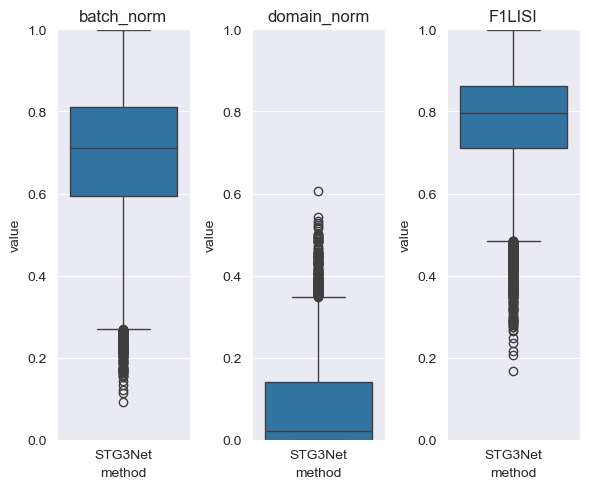

In [15]:
import harmonypy as hm


def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1) / num_batchs
    norm_domain = (LISI_domain_norm - 1) / num_domains
    LISI = 2 * (1 - norm_domain) * norm_batch / (1 - norm_domain + norm_batch)
    return LISI, norm_batch, norm_domain


LISI, norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'spiral', 'batch_name', 'layer_guess')

import seaborn as sns
import matplotlib.pyplot as plt

df_batch_norm = pd.DataFrame({
    'method': 'STG3Net',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STG3Net',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STG3Net',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\scanpy\plotting\_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\scanpy\plotting\_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\scanpy\plotting\_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\scanpy\plotting\_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


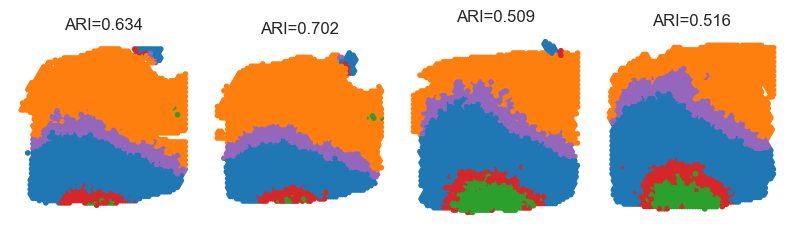

In [16]:
Batch_list = []
for section_id in sample_name:
    Batch_list.append(ann[ann.obs['batch'] == float(section_id)])

spot_size = 300
title_size = 12
ARI_list = []
for bb in range(len(sample_name)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['layer_guess'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(sample_name)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                         legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                         spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

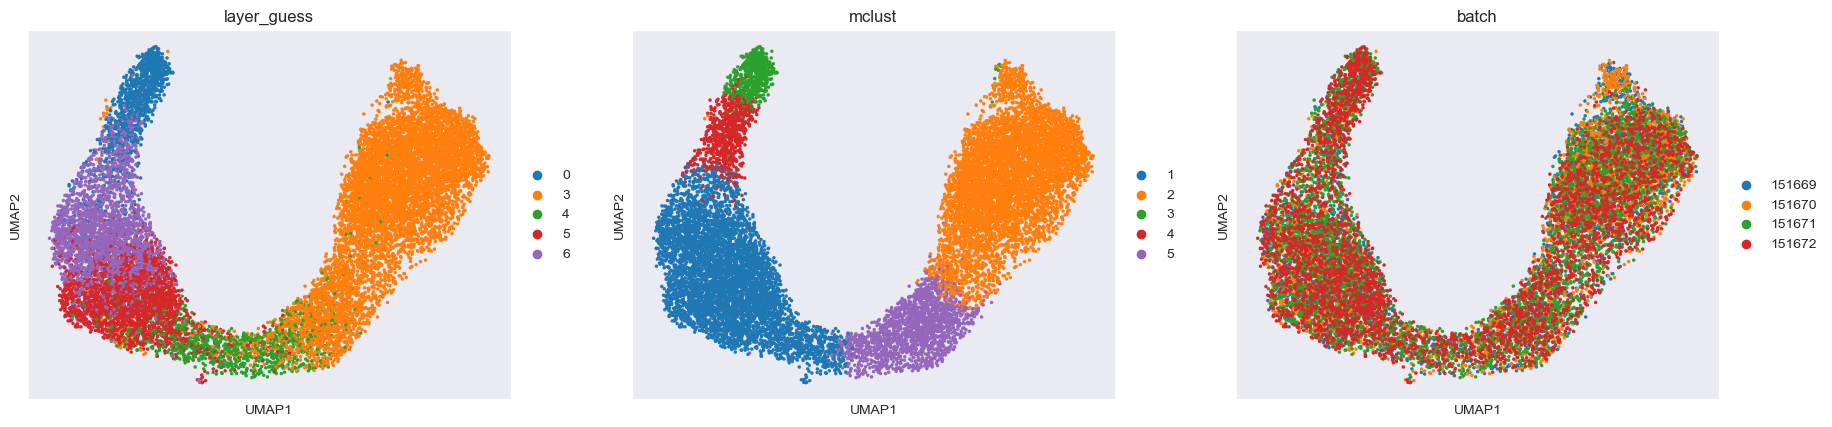

In [17]:
ann.obs['layer_guess'] = ann.obs['layer_guess'].astype(str)
ann.obs['batch'] = ann.obs['batch'].astype(str)

sc.pp.neighbors(ann, use_rep='spiral', metric='cosine')
sc.tl.umap(ann)
sc.pl.umap(ann, color=['layer_guess', 'mclust', 'batch'], show=True, size=25, save=False)

In [18]:
file_name = 'spiral_Donor2.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)